In [1]:
# =============================================================================
# CELL 0 -- Configuration, imports and style
#
# Produces both manuscript figures in one pass:
#   FIG 1  plots/diff_impact_parameters_visualization.png   (halo_skewers_example)
#   FIG 2  plots/HCD_detection.png                          (hcd_detection)
#
# Decomposition: "peaks+blend" -- velocity-space watershed with peak persistence
# plus the F_sep flux blending test of Sec. 2.3. This path has no density
# thresholds, so nothing here refers to a core trigger or an envelope floor.
# =============================================================================
%matplotlib widget

import os
import sys
from contextlib import contextmanager

import numpy as np
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import fftconvolve

REPO_DIR = os.path.abspath("..")          # notebooks_TNG/ -> FakeSpectra_DLAs/
sys.path.insert(0, os.path.join(REPO_DIR, "tools"))

import utils
import radii_skewers
from fake_spectra import spectra

if not hasattr(spectra, "HCD_ALGORITHMS"):
    raise ImportError(f"{spectra.__file__} is not the HCD fork "
                      "(no HCD_ALGORITHMS)")
print("using:", spectra.__file__)
print("algorithms:", spectra.HCD_ALGORITHMS)

# --- simulation --------------------------------------------------------------
SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"   # no "/output": groups_025/ lives here
SNAP_NUM  = 25                            # z ~ 3.01
SIM_TYPE  = "TNG"
RES_KMS   = 10.0

HCD_ALGORITHM = "peaks+blend"
# All three filter modes must share a kernel: the Voronoi kernel rebuilds its
# segments from whatever particles it is given, so a filtered subset would
# silently redistribute the removed volume onto the survivors.
KERNEL = "tophat"

# --- what to plot ------------------------------------------------------------
HALO_ID  = None        # None -> draw from the stratified pool
POSITION = None        # None -> random among Right/Left/Top/Bottom
SEED     = 12345

HALO_LOGM_RANGE = (11.5, 13.0)
N_CANDIDATES    = 40

NUM_PARAM_IMPACTS = 30
RANGE_PARAM_IMPACTS = (0.01, 50.0)
HCD_LOG_NHI = 17.2

# FIG 1
B_LIST_TARGET  = (0.01, 0.189)
MAP_AXIS       = 2        # 0=x, 1=y, 2=z. The caption says "along z".
MAP_HALF_R200  = 1.5
MAP_SLAB_R200  = 5.0      # matches the +/-5 R200 aperture of Sec. 2.4
MAP_NPIX       = 400      # fixed; smoothing is adaptive per cell
MAP_H_MAX_R200 = 0.25     # cap on a cell's smoothing radius, in R200
MAP_VMIN_LOGN  = 15.0     # colour floor; raise it if the panel saturates
MAP_VMAX_LOGN  = None     # None -> 99.9th pct of the pixels above the floor
SHOW_HCD_CONTOUR = True

# FIG 2
AXIS      = 1             # 1-indexed, as fake_spectra expects (1 = x)
B_TARGET  = 0.5           # snapped to the nearest production grid value
XLIM_FIG2 = None          # e.g. (-2000, 2000) km/s
FINE_ALIGN = True         # re-centre on the absorber, per Sec. 2.4

PLOT_DIR = os.path.join(REPO_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

# --- style -------------------------------------------------------------------
plt.rc('font', family='serif', size=16)
plt.rcParams.update({
    "mathtext.fontset": "cm", "text.usetex": False,
    "axes.linewidth": 1.6, "axes.grid": False,
    "axes.labelsize": 19, "legend.fontsize": 15,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 8, "ytick.major.size": 8,
    "xtick.minor.size": 4, "ytick.minor.size": 4,
    "xtick.major.width": 1.4, "ytick.major.width": 1.4,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "legend.frameon": True, "legend.framealpha": 0.92,
    "figure.dpi": 72, "savefig.dpi": 300, "savefig.bbox": "tight",
})

# Okabe-Ito, verbatim from the manuscript preamble.
colors = [
    "#E69F00",  # 0. Orange
    "#56B4E9",  # 1. Sky Blue
    "#009E73",  # 2. Bluish Green
    "#F0E442",  # 3. Yellow
    "#0072B2",  # 4. Blue
    "#D55E00",  # 5. Vermillion
    "#CC79A7",  # 6. Reddish Purple
    "#000000",  # 7. Black
    "#999999",  # 8. Grey
    "#553388",  # 9. Purple
]
OI = {"orange": colors[0], "sky": colors[1], "green": colors[2],
      "yellow": colors[3], "blue": colors[4], "vermillion": colors[5],
      "purple": colors[6], "black": colors[7], "grey": colors[8],
      "violet": colors[9]}
plt.rcParams["axes.prop_cycle"] = mpl.cycler(color=colors)

M_SUN_G, KPC_CM, M_P_G = 1.98847e33, 3.085678e21, 1.67262192e-24
X_H_DEFAULT = 0.76

using: /home/vroberto/fake_spectra_fork/fake_spectra/spectra.py
algorithms: ('peaks', 'peaks+blend', 'region_growing')


In [2]:
# =============================================================================
# CELL 1 -- Capture the cells fake_spectra actually interpolated
#
# The fork discards its internal mask, so we read it off the three filter modes:
#   "None"        -> every cell near the sightline
#   "HCD_only"    -> the cells the filter flagged
#   "Forest_only" -> the complement
#
# THREE TRAPS:
#  1. Shapes. Each mode runs three passes (tau, column density, temperature);
#     only the tau pass carries full velocities and temperatures. Keep get_tau
#     only, or concatenating mixes (N,3) with (1,).
#  2. Units. elem_den is in code units, and in the get_temp pass it is not even
#     n_HI. Physical n_HI = (elem_den / rscale) * amumass.
#  3. Re-entrancy. Under peaks+blend the fork's _blend_test calls the
#     interpolator once per CANDIDATE basin while still deciding the mask.
#     Those are hypotheses, not the answer; drop anything captured inside it.
# =============================================================================
@contextmanager
def suppress_c_stdout():
    """Silence the C interpolator's progress printing (it writes to fd 1)."""
    sys.stdout.flush()
    saved = os.dup(1)
    devnull = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 1)
        yield
    finally:
        os.dup2(saved, 1)
        os.close(devnull)
        os.close(saved)


@contextmanager
def capture_cells(store):
    original_interp = spectra.Spectra._do_interpolation_work
    original_blend = getattr(spectra.Spectra, "_blend_test", None)
    state = {"in_blend": False, "n_blend": 0}

    def interp_wrapper(self, pos, vel, elem_den, temp, hh, amumass, line,
                       get_tau, custom_axis=None, custom_cofm=None):
        if state["in_blend"]:
            state["n_blend"] += 1
        else:
            store.append(dict(
                get_tau=bool(get_tau), amumass=float(amumass),
                rscale=float(self.rscale),
                pos=np.array(pos, copy=True), vel=np.array(vel, copy=True),
                den=np.array(elem_den, copy=True),
                temp=np.array(temp, copy=True)))
        return original_interp(self, pos, vel, elem_den, temp, hh, amumass,
                               line, get_tau, custom_axis=custom_axis,
                               custom_cofm=custom_cofm)

    def blend_wrapper(self, *a, **kw):
        prev = state["in_blend"]
        state["in_blend"] = True
        try:
            return original_blend(self, *a, **kw)
        finally:
            state["in_blend"] = prev

    spectra.Spectra._do_interpolation_work = interp_wrapper
    if original_blend is not None:
        spectra.Spectra._blend_test = blend_wrapper
    try:
        yield store
    finally:
        spectra.Spectra._do_interpolation_work = original_interp
        if original_blend is not None:
            spectra.Spectra._blend_test = original_blend
        if state["n_blend"]:
            print(f"    (dropped {state['n_blend']} blend-test interpolations)")


EMPTY_CELLS = dict(pos=np.empty((0, 3)), vel=np.empty((0, 3)),
                   nHI=np.empty(0), temp=np.empty(0))


def merge_captures(store):
    """Keep the get_tau pass, convert the density to physical n_HI [cm^-3]."""
    chunks = [c for c in store if c["get_tau"]]
    if not chunks:
        return dict(EMPTY_CELLS)
    for c in chunks:
        n = c["pos"].shape[0]
        if c["vel"].shape[0] != n or c["temp"].shape[0] != n:
            raise RuntimeError("ragged get_tau chunk; the fork's interpolation "
                               "signature changed -- update this wrapper")
    out = {k: np.concatenate([c[k] for c in chunks], axis=0)
           for k in ("pos", "vel", "temp")}
    out["nHI"] = np.concatenate(
        [(c["den"] / c["rscale"]) * c["amumass"] for c in chunks], axis=0)
    return out

In [3]:
# =============================================================================
# CELL 2 -- Impact-parameter grid, halo selection, sightline construction
#
# get_stratified_halo_indices(base_dir, snap_number, bins_log, n_per_bin,
#                             exhaustive_threshold, rng_seed)
# -- all positional, returns a THREE-tuple.
# =============================================================================
def build_r_multipliers(n_impacts, impact_min, impact_max):
    return np.insert(np.logspace(np.log10(impact_min), np.log10(impact_max),
                                 n_impacts), 0, 0.0)


R_MULTIPLIERS = build_r_multipliers(NUM_PARAM_IMPACTS, *RANGE_PARAM_IMPACTS)


def snap_impact(b_target, grid=R_MULTIPLIERS):
    """Nearest grid value to b_target, in log space (the grid is log-spaced)."""
    pos = grid[grid > 0]
    k = int(np.argmin(np.abs(np.log10(pos) - np.log10(b_target))))
    return float(pos[k]), k


def wrap(d, period):
    """Signed separation on a periodic axis, in (-period/2, +period/2]."""
    return (np.asarray(d) + period / 2.0) % period - period / 2.0


B_USED, B_INDEX = snap_impact(B_TARGET)
B_LIST = [snap_impact(b)[0] for b in B_LIST_TARGET]
print(f"FIG 2 b: {B_TARGET} -> {B_USED:.4f} R200 (grid index {B_INDEX})")
print(f"FIG 1 b: {B_LIST_TARGET} -> {[f'{b:.4f}' for b in B_LIST]} R200")

ctx = utils.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
finder = utils.HaloFinder(ctx)

for _p in (os.path.join(BASE_PATH, f"groups_{SNAP_NUM:03d}",
                        f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5"),
           os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}")):
    if not os.path.exists(_p):
        raise FileNotFoundError(f"not found: {_p}\nCheck BASE_PATH={BASE_PATH!r}")

if HALO_ID is None:
    import run_parallel_illustris as rpi
    lo, hi = HALO_LOGM_RANGE
    candidates, total_halos, _ = rpi.get_stratified_halo_indices(
        BASE_PATH, SNAP_NUM, [(lo, hi)], N_CANDIDATES, 0, SEED)
    candidates = np.asarray(candidates, dtype=int).ravel()
    print(f"{len(candidates)} candidates in log10 M200 = [{lo}, {hi}] "
          f"({total_halos:,} haloes in the catalogue)")
else:
    candidates = np.array([HALO_ID], dtype=int)

POSITION_TAGS = ("Right", "Left", "Top", "Bottom")
position = POSITION if POSITION is not None else str(rng.choice(POSITION_TAGS))
print(f"FIG 2 sightline: axis {AXIS} (1 = x), position {position}")


def sightline_for(halo_info, axis_1indexed, b_mult, tag):
    """cofm and axis arrays for one skewer, using the production geometry."""
    g = radii_skewers.SkewerGeometry(ctx, halo_info)
    for sk in g.generate_skewers(r_multiplier=b_mult):
        if sk['axis'] == axis_1indexed - 1 and sk['position_tag'] == tag:
            cofm = np.mod(np.asarray(halo_info['cm'], float) + sk['offset_vec'],
                          halo_info['box_size'])
            return (np.array([cofm], dtype=np.float64),
                    np.array([axis_1indexed], dtype=np.int32), sk)
    raise RuntimeError(f"no skewer with axis={axis_1indexed}, tag={tag}")

FIG 2 b: 0.5 -> 0.4552 R200 (grid index 13)
FIG 1 b: (0.01, 0.189) -> ['0.0100', '0.1886'] R200
Scanning 1,361,174 halos across 128 catalog chunk(s)...
  h = 0.6774, converting bins to code units (10^10 M_sun/h)

--- Mass Stratification (seed=12345, h=0.6774, sim=TNG50-2) ---
  Bin [10^11.5 - 10^13.0] M_sun :    251 available ->   40 drawn  
40 candidates in log10 M200 = [11.5, 13.0] (1,361,174 haloes in the catalogue)
FIG 2 sightline: axis 1 (1 = x), position Top


In [4]:
# =============================================================================
# CELL 3 -- Run the pipeline three times on one sightline (FIG 2)
#
# Each filter_mode is an independent pass over the snapshot: the filter decides
# which cells reach the C interpolator, so the modes cannot share a pass.
#
# meta is built piecewise because the HCD attributes only exist on a filtered
# Spectra -- reading them from the "None" pass raises AttributeError.
# =============================================================================
MODES = ("None", "HCD_only", "Forest_only")


def run_one_sightline(halo_info, cofm, axis_arr):
    out, meta = {}, {}
    for mode in MODES:
        store = []
        with capture_cells(store), suppress_c_stdout():
            ss = spectra.Spectra(
                int(SNAP_NUM), BASE_PATH, cofm=cofm, axis=axis_arr,
                res=RES_KMS, savefile=f"unused_{halo_info['id']}_{mode}.hdf5",
                reload_file=True, kernel=KERNEL, MPI=None, quiet=True,
                filter_mode=mode, hcd_algorithm=HCD_ALGORITHM,
                units=ctx.units, halo_r200=float(halo_info['r200']),
                halo_radius_cut=5.0)
            tau = ss.get_tau("H", 1, 1215)[0]
            colden = ss.get_col_density("H", 1)[0]
            temp = ss.get_temp("H", 1)[0]

        out[mode] = dict(flux=np.exp(-tau), tau=tau, colden=colden, temp=temp,
                         cells=merge_captures(store))

        if not meta:      # geometry and cosmology: identical in all modes
            meta = dict(nbins=ss.nbins, vmax=ss.vmax, velfac=ss.velfac,
                        box=ss.box, red=ss.red, rscale=ss.rscale)
        if mode == "HCD_only":
            meta.update(
                selection_thresh=ss.hcd_selection_thresh,
                peak_smooth_kms=ss.hcd_peak_smooth_kms,
                peak_contrast=ss.hcd_peak_contrast,
                blend_flux_thresh=ss.hcd_blend_flux_thresh,
                basin_info=dict(getattr(ss, "hcd_basin_info", {})))

        tot = colden.sum()
        print(f"  {mode:12s} -> {out[mode]['cells']['pos'].shape[0]:6d} cells, "
              f"log10 N_HI = {np.log10(tot) if tot > 0 else -np.inf:.2f}")
    return out, meta


res = meta = halo_info = sk_info = None
for hid in candidates:
    hi_info = finder.get_halo_properties(int(hid))
    cofm, axis_arr, sk = sightline_for(hi_info, AXIS, B_USED, position)
    print(f"halo {int(hid)}  log10 M200 = "
          f"{np.log10(hi_info['mass'] * 1e10 / 0.6774):.2f}")
    r, m = run_one_sightline(hi_info, cofm, axis_arr)
    n_tot = r["HCD_only"]["colden"].sum()
    if HALO_ID is not None or (n_tot > 0 and np.log10(n_tot) >= HCD_LOG_NHI):
        res, meta, halo_info, sk_info = r, m, hi_info, sk
        print(f"--> using halo {int(hid)}")
        break
    print("    no HCD on this sightline, next halo")

if res is None:
    raise RuntimeError("no candidate hosts an HCD here; widen HALO_LOGM_RANGE "
                       "or lower B_TARGET")

# The decomposition must be a partition. A mismatch means the three modes did
# not see the same particle set, almost always a kernel mismatch.
na = res["None"]["cells"]["pos"].shape[0]
nh = res["HCD_only"]["cells"]["pos"].shape[0]
nf = res["Forest_only"]["cells"]["pos"].shape[0]
print(f"\ncells: total={na}, HCD={nh}, forest={nf}, HCD+forest-total={nh+nf-na}")
c_all = res["None"]["colden"].sum()
if c_all > 0:
    c_sum = res["HCD_only"]["colden"].sum() + res["Forest_only"]["colden"].sum()
    print(f"N_HI closure: (HCD+forest)/total - 1 = {c_sum / c_all - 1:.3e}")
print(f"basins found: {len(meta.get('basin_info', {}).get(0, []))}")

halo 49  log10 M200 = 11.86
rank = 0 | Interpolation 0.8 percent done
rank = 0 | Interpolation 1.6 percent done
rank = 0 | Interpolation 2.3 percent done
rank = 0 | Interpolation 3.1 percent done
rank = 0 | Interpolation 3.9 percent done
rank = 0 | Interpolation 4.7 percent done
rank = 0 | Interpolation 5.5 percent done
rank = 0 | Interpolation 6.2 percent done
rank = 0 | Interpolation 7.0 percent done
rank = 0 | Interpolation 7.8 percent done
rank = 0 | Interpolation 8.6 percent done
rank = 0 | Interpolation 9.4 percent done
rank = 0 | Interpolation 10.2 percent done
rank = 0 | Interpolation 10.9 percent done
rank = 0 | Interpolation 11.7 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 13.3 percent done
rank = 0 | Interpolation 14.1 percent done
rank = 0 | Interpolation 14.8 percent done
rank = 0 | Interpolation 15.6 percent done
rank = 0 | Interpolation 16.4 percent done
rank = 0 | Interpolation 17.2 percent done
rank = 0 | Interpolation 18.0 percent 

In [5]:
# =============================================================================
# CELL 4 -- FIG 1 spectra: 12 skewers at each of the two impact parameters
#
# Goes through run_analysis_batched, the production path, so these profiles are
# identical to the catalogues: one snapshot read for all 24 sightlines, and the
# 10^17.2 cut applied non-destructively -- sightlines below it come back flat at
# F = 1, which is why some curves sit exactly on unity.
# =============================================================================
geom = radii_skewers.SkewerGeometry(ctx, halo_info)

skewers_fig1 = []
for b in B_LIST:
    skewers_fig1.extend(geom.generate_skewers(r_multiplier=b))
print(f"FIG 1: {len(skewers_fig1)} skewers")

with suppress_c_stdout():
    meta1, rows1 = geom.run_analysis_batched(
        skewers_fig1, modes=("HCD_only",), products=("colden", "tau"),
        zero_below_cut=True)

v_grid1 = np.asarray(meta1['v_grid'], dtype=float)
by_b = {b: [r for r in rows1 if np.isclose(r['r_multiplier'], b)]
        for b in B_LIST}
for b, rr in by_b.items():
    print(f"  b = {b:.3f} R200: {len(rr)} skewers, "
          f"{sum(r['is_hcd'] for r in rr)} with an HCD")

FIG 1: 24 skewers
--> [Halo 49] extracting 24 skewers (HCD_only) in RAM...
  b = 0.010 R200: 12 skewers, 12 with an HCD
  b = 0.189 R200: 12 skewers, 10 with an HCD


In [6]:
# =============================================================================
# CELL 5 -- FIG 1 map: projected neutral hydrogen column density
#
#     N_atoms = Masses[1e10 Msun/h] * 1e10 * M_sun / h * X_H * x_HI / m_p
#     N_HI    = N_atoms / (physical pixel area)
#
# Cells inside a slab of +/- MAP_SLAB_R200 along the projection axis contribute,
# matching the +/-5 R200 aperture of Sec. 2.4.
#
# THE float32 OVERFLOW. Masses is float32 in the snapshot and numpy keeps
# float32 through a multiplication by a Python scalar. Written left to right,
# mass * 1e10 * M_SUN_G reaches ~1.4e39 for a TNG50-2 gas cell, past the float32
# ceiling of 3.4e38, and returns inf. One inf makes the whole map NaN, which
# gives a black panel and a +/-0.1 colourbar. Cast to float64 and fold the
# constants so no intermediate leaves range.
#
# DEPOSITION. Each cell is spread over the projected disc of its top-hat kernel,
# radius h = V^(1/3) as in Sec. 2.2. Point deposition on a grid finer than a
# cell lights one pixel and leaves its neighbours empty. Cells are grouped by
# stamp radius and each group is convolved once with its normalised disc by FFT:
# exact to 1e-6 away from the border, and 300k cells on a 400^2 grid in 0.2 s.
# =============================================================================
ATOMS_PER_CODE_MASS = 1e10 * M_SUN_G / M_P_G      # divided by h below

snap_dir = os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}")
with h5py.File(os.path.join(snap_dir, f"snap_{SNAP_NUM:03d}.0.hdf5"), 'r') as f:
    hdr = f['Header'].attrs
    n_files = int(hdr.get('NumFilesPerSnapshot', hdr.get('NumFiles', 1)))
    hubble = float(hdr.get('HubbleParam', 0.6774))
    a_scale = float(hdr.get('Time', 1.0))
    box_code = float(hdr['BoxSize'])

cen = np.asarray(halo_info['cm'], dtype=float)
r200 = float(halo_info['r200'])
ax_p, ax_q = [k for k in range(3) if k != MAP_AXIS]
half = MAP_HALF_R200 * r200
slab = MAP_SLAB_R200 * r200
pix_code = (2.0 * half) / MAP_NPIX
edges = np.linspace(-half, half, MAP_NPIX + 1)


def _read_region(fp):
    with h5py.File(fp, 'r') as f:
        if 'PartType0' not in f:
            return None
        g = f['PartType0']
        co = g['Coordinates'][:]
        dp = wrap(co[:, ax_p] - cen[ax_p], box_code)
        dq = wrap(co[:, ax_q] - cen[ax_q], box_code)
        dl = wrap(co[:, MAP_AXIS] - cen[MAP_AXIS], box_code)
        m = (np.abs(dp) <= half) & (np.abs(dq) <= half) & (np.abs(dl) <= slab)
        if not m.any():
            return None

        mass = g['Masses'][:][m].astype(np.float64)
        dens = g['Density'][:][m].astype(np.float64)
        xHI = g['NeutralHydrogenAbundance'][:][m].astype(np.float64)
        XH = (g['GFM_Metals'][:, 0][m].astype(np.float64) if 'GFM_Metals' in g
              else np.full(int(m.sum()), X_H_DEFAULT, dtype=np.float64))

        # h = V^(1/3), V = mass / density. np.where evaluates both branches, so
        # the divisor is guarded too, not just the result.
        safe = np.where(dens > 0, dens, 1.0)
        h_code = np.cbrt(np.where(dens > 0, mass / safe, 0.0))

        n_atoms = mass * (ATOMS_PER_CODE_MASS / hubble) * XH * xHI
        return dp[m], dq[m], h_code, n_atoms


chunks = []
for i in range(n_files):
    fp = os.path.join(snap_dir, f"snap_{SNAP_NUM:03d}.{i}.hdf5")
    if os.path.exists(fp):
        c = _read_region(fp)
        if c is not None:
            chunks.append(c)
if not chunks:
    raise RuntimeError("no gas cells in the mapped region -- check MAP_AXIS/cen")

dp_a = np.concatenate([c[0] for c in chunks])
dq_a = np.concatenate([c[1] for c in chunks])
h_a = np.concatenate([c[2] for c in chunks])
w_a = np.concatenate([c[3] for c in chunks])
del chunks

good = np.isfinite(w_a) & (w_a > 0) & np.isfinite(h_a)
n_bad = int((~np.isfinite(w_a)).sum())
if n_bad == w_a.size:
    raise RuntimeError("EVERY weight is non-finite -- this is the float32 "
                       "overflow; check the .astype(np.float64) casts above")
if n_bad:
    print(f"WARNING: dropped {n_bad} cells with non-finite weight")
dp_a, dq_a, h_a, w_a = dp_a[good], dq_a[good], h_a[good], w_a[good]

# Void cells can be hundreds of kpc across; uncapped, a few of them smear a
# uniform haze over the panel. Cap the CELL, not the stamp, so the kernel stays
# normalised and the atom count is still conserved.
h_cap = MAP_H_MAX_R200 * r200
n_capped = int((h_a > h_cap).sum())
h_a = np.minimum(h_a, h_cap)

print(f"cells: {dp_a.size:,} | median h = "
      f"{np.median(h_a) * ctx.length_unit_kpc:.2f} ckpc/h | pixel = "
      f"{pix_code * ctx.length_unit_kpc:.2f} ckpc/h "
      f"({np.median(h_a) / pix_code:.1f} px) | capped {n_capped:,}")

ip = np.clip(((dp_a + half) / pix_code).astype(np.int64), 0, MAP_NPIX - 1)
jq = np.clip(((dq_a + half) / pix_code).astype(np.int64), 0, MAP_NPIX - 1)
Rpix = np.rint(h_a / pix_code).astype(np.int64)


def _disc(R):
    yy, xx = np.mgrid[-R:R + 1, -R:R + 1]
    k = ((xx ** 2 + yy ** 2) <= R ** 2).astype(float)
    return k / k.sum()          # unit sum -> the atom count is conserved


Nmap = np.zeros((MAP_NPIX, MAP_NPIX))
for R in np.unique(Rpix):
    sel = Rpix == R
    G = np.zeros((MAP_NPIX, MAP_NPIX))
    np.add.at(G, (ip[sel], jq[sel]), w_a[sel])
    Nmap += G if R == 0 else fftconvolve(G, _disc(int(R)), mode='same')
Nmap = np.clip(Nmap, 0.0, None)     # FFT ringing can leave tiny negatives
print(f"deposition: {len(np.unique(Rpix))} radius groups, atoms retained = "
      f"{Nmap.sum() / w_a.sum():.4f}")

pix_cm = pix_code * ctx.length_unit_kpc / hubble * a_scale * KPC_CM
Nmap /= pix_cm ** 2

# Floor rather than NaN: empty pixels render as the bottom of the colour map
# instead of as holes, and the contour has a defined field everywhere.
floor = 10.0 ** MAP_VMIN_LOGN
logN = np.log10(np.maximum(Nmap, floor))
above = Nmap > floor

if MAP_VMAX_LOGN is not None:
    vmax_logN = float(MAP_VMAX_LOGN)
elif above.any():
    vmax_logN = float(np.percentile(logN[above], 99.9))
else:
    vmax_logN = MAP_VMIN_LOGN + 1.0
if not np.isfinite(vmax_logN) or vmax_logN <= MAP_VMIN_LOGN:
    vmax_logN = MAP_VMIN_LOGN + 1.0
    print("WARNING: colour scale degenerate; the map is essentially empty")

print(f"log10 N_HI in [{logN.min():.2f}, {logN.max():.2f}], "
      f"scale [{MAP_VMIN_LOGN:.1f}, {vmax_logN:.2f}]")
print(f"pixels above the floor: {100 * above.mean():.1f}% | "
      f"above 10^{HCD_LOG_NHI}: {100 * np.mean(logN >= HCD_LOG_NHI):.2f}%")

cells: 298,910 | median h = 5.87 ckpc/h | pixel = 1.41 ckpc/h (4.2 px) | capped 559
deposition: 34 radius groups, atoms retained = 0.9988
log10 N_HI in [15.00, 21.34], scale [15.0, 20.96]
pixels above the floor: 97.1% | above 10^17.2: 35.33%


saved /home/vroberto/FakeSpectra_DLAs/plots/diff_impact_parameters_visualization.png


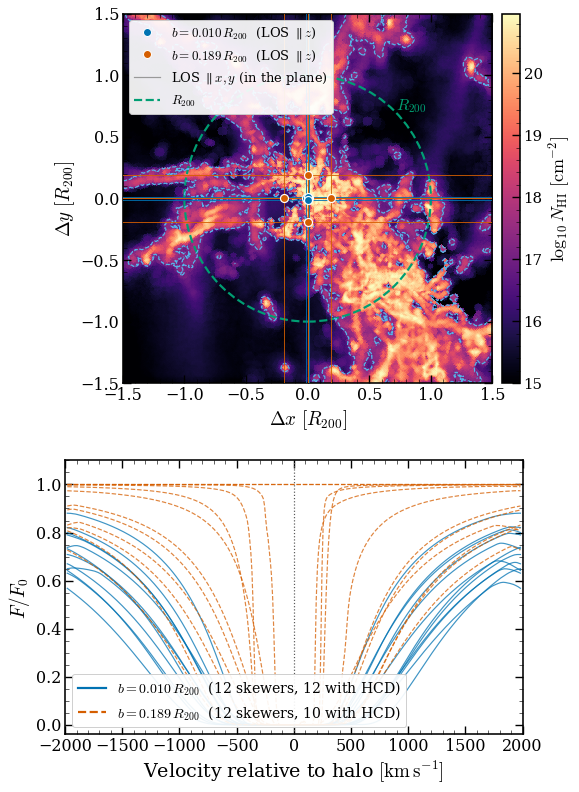

In [7]:
# =============================================================================
# CELL 6 -- FIG 1  (plots/diff_impact_parameters_visualization.png)
#
# Elements drawn, all of which the caption must name:
#   colour map      projected log10 N_HI in a +/-5 R200 slab
#   dashed circle   R200
#   filled circles  the 4 sightlines whose LOS is the projection axis
#   straight lines  the 8 sightlines lying in the plane of the map
#   dashed contour  the 10^17.2 cm^-2 HCD threshold  (SHOW_HCD_CONTOUR)
#   thin curves     individual HCD-only transmitted-flux profiles
#
# No mean profile: averaging over sightlines that do and do not host an HCD
# gives a curve that describes none of them, and the legend already reports the
# incidence.
# =============================================================================
plt.close('all')

B_COLORS = {B_LIST[0]: OI["blue"], B_LIST[1]: OI["vermillion"]}
B_LS = {B_LIST[0]: "-", B_LIST[1]: "--"}
AXNAME = "xyz"

fig1, (axm, axf) = plt.subplots(
    2, 1, figsize=(8.2, 13.0),
    gridspec_kw=dict(height_ratios=[1.35, 1.0], hspace=0.24))

# --- map panel ---------------------------------------------------------------
cmap = mpl.colormaps['magma'].copy()
cmap.set_bad(cmap(0.0))

im = axm.imshow(logN.T, origin='lower', cmap=cmap,
                extent=[-MAP_HALF_R200, MAP_HALF_R200,
                        -MAP_HALF_R200, MAP_HALF_R200],
                vmin=MAP_VMIN_LOGN, vmax=vmax_logN,
                aspect='equal', interpolation='nearest')
cb = fig1.colorbar(im, ax=axm, fraction=0.046, pad=0.02)
cb.set_label(r'$\log_{10} N_{\rm HI}\ [\mathrm{cm^{-2}}]$', fontsize=18)
cb.ax.tick_params(labelsize=15)

if SHOW_HCD_CONTOUR:
    cc = 0.5 * (edges[1:] + edges[:-1]) / r200
    axm.contour(cc, cc, logN.T, levels=[HCD_LOG_NHI],
                colors=[OI["sky"]], linewidths=1.2, linestyles='--')

axm.add_patch(plt.Circle((0, 0), 1.0, fill=False, ec=OI["green"], lw=2.2,
                         ls='--'))
axm.text(0.72, 0.72, r'$R_{200}$', color=OI["green"], fontsize=16)

for b in B_LIST:
    c = B_COLORS[b]
    for sk in by_b[b]:
        off = np.zeros(3)
        free = [k for k in range(3) if k != sk['axis']]
        tag = sk['position_tag']
        off[free[0]] = b if tag == "Right" else (-b if tag == "Left" else 0.0)
        off[free[1]] = b if tag == "Top" else (-b if tag == "Bottom" else 0.0)
        if sk['axis'] == MAP_AXIS:
            axm.plot(off[ax_p], off[ax_q], 'o', ms=8, mfc=c, mec='white',
                     mew=1.2, zorder=6)
        elif sk['axis'] == ax_p:
            axm.axhline(off[ax_q], color=c, lw=1.0, alpha=0.85, zorder=4)
        else:
            axm.axvline(off[ax_p], color=c, lw=1.0, alpha=0.85, zorder=4)

axm.set_xlim(-MAP_HALF_R200, MAP_HALF_R200)
axm.set_ylim(-MAP_HALF_R200, MAP_HALF_R200)
axm.set_xlabel(rf'$\Delta {AXNAME[ax_p]}\ [R_{{200}}]$')
axm.set_ylabel(rf'$\Delta {AXNAME[ax_q]}\ [R_{{200}}]$')
axm.legend(
    [Line2D([], [], ls='none', marker='o', ms=8, mfc=B_COLORS[B_LIST[0]],
            mec='white'),
     Line2D([], [], ls='none', marker='o', ms=8, mfc=B_COLORS[B_LIST[1]],
            mec='white'),
     Line2D([], [], color=OI["grey"], lw=1.2),
     Line2D([], [], color=OI["green"], lw=2.2, ls='--')],
    [rf'$b = {B_LIST[0]:.3f}\,R_{{200}}$  (LOS $\parallel {AXNAME[MAP_AXIS]}$)',
     rf'$b = {B_LIST[1]:.3f}\,R_{{200}}$  (LOS $\parallel {AXNAME[MAP_AXIS]}$)',
     rf'LOS $\parallel {AXNAME[ax_p]},{AXNAME[ax_q]}$ (in the plane)',
     r'$R_{200}$'],
    loc='upper left', fontsize=13)

# --- flux panel: individual sightlines only ----------------------------------
handles, labels = [], []
for b in B_LIST:
    c, ls = B_COLORS[b], B_LS[b]
    for r in by_b[b]:
        axf.plot(v_grid1, np.asarray(r['flux'], float),
                 color=c, ls=ls, lw=1.2, alpha=0.75, zorder=2)
    handles.append(Line2D([], [], color=c, ls=ls, lw=2.2))
    labels.append(rf'$b = {b:.3f}\,R_{{200}}$  ({len(by_b[b])} skewers, '
                  rf'{sum(r["is_hcd"] for r in by_b[b])} with HCD)')

axf.axvline(0.0, color='0.35', lw=1.2, ls=':')
axf.set_xlim(-2000, 2000)
axf.set_ylim(-0.04, 1.10)
axf.set_xlabel(r'Velocity relative to halo $[\mathrm{km\,s^{-1}}]$')
axf.set_ylabel(r'$F/F_0$')
axf.legend(handles, labels, loc='lower left', fontsize=14)

for ax in (axm, axf):
    ax.grid(False)
    for s in ax.spines.values():
        s.set_linewidth(1.6)

out1 = os.path.join(PLOT_DIR, "diff_impact_parameters_visualization.png")
fig1.savefig(out1, dpi=300, bbox_inches='tight')
if hasattr(fig1.canvas, "header_visible"):
    fig1.canvas.header_visible = False
print(f"saved {out1}")
plt.show()

In [ ]:
# =============================================================================
# CELL 6b -- which halo does FIG 1 use, and what are its R200 / M200?
#
# FIG 1 does not select its own halo: it reuses halo_info exactly as chosen
# in Cell 3 for FIG 2 (the "--> using halo ..." line there), only the impact
# parameters differ (B_LIST here vs. B_TARGET for FIG 2). So yes -- same halo
# in both figures. This cell just prints its R200 and M200 so the numbers can
# be checked against the manuscript caption without scrolling back to Cell 3/8.
# =============================================================================
print(f"FIG 1 halo: {halo_info['id']}  (identical halo_info used for FIG 2)")
print(f"  log10(M200/Msun) = {np.log10(halo_info['mass'] * 1e10 / 0.6774):.2f}")
print(f"  R200             = {r200 * ctx.length_unit_kpc:.1f} ckpc/h "
      f"({r200:.4f} in code units)")


In [8]:
# =============================================================================
# CELL 7 -- FIG 2: put the cells AND the spectra in the halo rest frame
#
# Both panels must live in the same frame:
#   a cell absorbs at  u_i   = velfac * chi_i    + v_pec,i
#   the halo sits at   v_sys = velfac * chi_halo + v_pec,halo
#   so                 dv_i  = wrap(u_i - v_sys)
#
# The flux array is indexed by box-frame velocity, so the same shift applies to
# it, resampled rather than scattered. center_on_halo pads periodically because
# np.interp does not wrap and would otherwise clip both ends of the axis.
#
# FINE_ALIGN is the second step of Sec. 2.4: internal motions offset the deepest
# absorption from the systemic velocity by tens of km/s, so both panels are
# shifted by the centre of the HCD-only trough.
# =============================================================================
k_los = AXIS - 1
box = meta['box']
a_of_z = 1.0 / (1.0 + meta['red'])

v_cosmo = (halo_info['cm'][k_los] / box) * meta['vmax']
v_pec_halo = halo_info['vel_raw'][k_los] * np.sqrt(a_of_z)
V_SYS = v_cosmo + v_pec_halo

v_axis = np.arange(meta['nbins']) * (meta['vmax'] / meta['nbins'])
v_grid = np.linspace(-meta['vmax'] / 2.0, meta['vmax'] / 2.0, meta['nbins'])


def center_on_halo(y):
    dv = wrap(v_axis - V_SYS, meta['vmax'])
    o = np.argsort(dv)
    dvs, ys = dv[o], np.asarray(y, dtype=float)[o]
    dvs = np.concatenate([dvs - meta['vmax'], dvs, dvs + meta['vmax']])
    ys = np.concatenate([ys, ys, ys])
    return np.interp(v_grid, dvs, ys)


def cell_coords(cells):
    """(Delta v [km/s], n_HI [cm^-3]) for one captured cell set, halo frame."""
    if cells['pos'].shape[0] == 0:
        return np.empty(0), np.empty(0)
    chi = wrap(cells['pos'][:, k_los] - halo_info['cm'][k_los], box)
    return (wrap(chi * meta['velfac'] + cells['vel'][:, k_los] - v_pec_halo,
                 meta['vmax']),
            cells['nHI'])


flux_c = {m: center_on_halo(res[m]["flux"]) for m in MODES}
x_hcd, n_hcd = cell_coords(res["HCD_only"]["cells"])
x_for, n_for = cell_coords(res["Forest_only"]["cells"])

# The trough centre, not argmin: a saturated core is flat over many pixels.
if FINE_ALIGN and np.nanmin(flux_c["HCD_only"]) < 0.99:
    f = flux_c["HCD_only"]
    deep = np.where(f <= np.nanmin(f) + 0.01 * (1.0 - np.nanmin(f)))[0]
    dv_shift = 0.5 * (v_grid[deep[0]] + v_grid[deep[-1]])

    def _reshift(y):
        gg = np.concatenate([v_grid - meta['vmax'], v_grid,
                             v_grid + meta['vmax']])
        return np.interp(v_grid, gg - dv_shift, np.concatenate([y, y, y]))

    flux_c = {m: _reshift(v) for m, v in flux_c.items()}
    x_hcd = wrap(x_hcd - dv_shift, meta['vmax'])
    x_for = wrap(x_for - dv_shift, meta['vmax'])
    print(f"fine alignment: {dv_shift:+.1f} km/s")
else:
    dv_shift = 0.0

# The N_HI-weighted mean velocity of the HCD cells and the trough centre must
# now agree to within a pixel or two.
if n_hcd.size:
    print(f"HCD cells: N_HI-weighted <dv> = "
          f"{np.sum(x_hcd * n_hcd) / np.sum(n_hcd):+.1f} km/s "
          f"(pixel = {meta['vmax'] / meta['nbins']:.1f} km/s)")

fine alignment: +25.1 km/s
HCD cells: N_HI-weighted <dv> = +44.1 km/s (pixel = 10.0 km/s)


saved /home/vroberto/FakeSpectra_DLAs/plots/HCD_detection.png


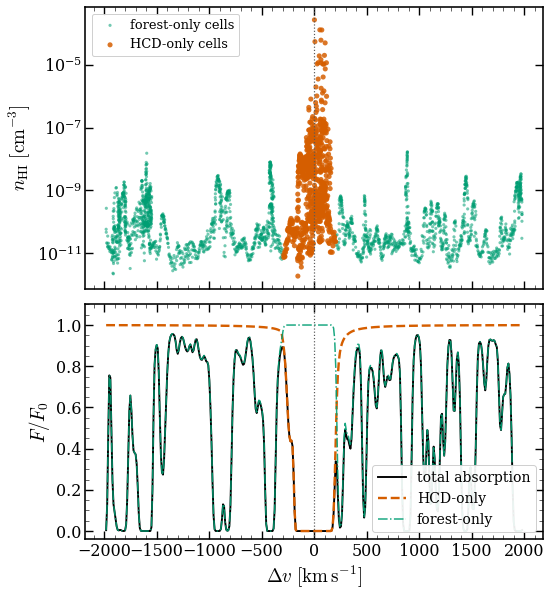


halo 49  log10 M200 = 11.86  R200 = 188.3 ckpc/h
FIG 2 sightline: axis 1, Top, b = 0.4552 R200
v_sys = 149.1 km/s, fine alignment = +25.1 km/s
  None         log10 N_HI = 18.05
  HCD_only     log10 N_HI = 18.05
  Forest_only  log10 N_HI = 15.91


In [9]:
# =============================================================================
# CELL 8 -- FIG 2  (plots/HCD_detection.png)
#
# Elements drawn, all of which the caption must name:
#   green points     cells returned to the forest channel
#   orange points    cells the filter assigned to the HCD channel
#   dotted vertical  the halo rest frame, after the alignment of Sec. 2.4
#   three curves     total, HCD-only and forest-only transmitted flux
#
# No core trigger or envelope floor: the peaks+blend procedure carries no
# density threshold, so that part of the current caption is obsolete and the
# caption needs rewriting rather than the figure.
# =============================================================================
plt.close('all')

LS = {"total": "-", "hcd": "--", "forest": "-."}

fig2, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(8.2, 9.6), sharex=True,
    gridspec_kw=dict(height_ratios=[1.2, 1.0], hspace=0.06))

ax0.scatter(x_for, n_for, s=10, color=OI["green"], alpha=0.55,
            edgecolor='none', rasterized=True, label='forest-only cells')
ax0.scatter(x_hcd, n_hcd, s=26, color=OI["vermillion"], alpha=0.85,
            edgecolor='none', rasterized=True, label='HCD-only cells')
ax0.axvline(0.0, color='0.35', lw=1.2, ls=':')
ax0.set_yscale('log')
ax0.set_ylabel(r'$n_{\rm HI}\ [\mathrm{cm^{-3}}]$')
ax0.legend(loc='upper left', fontsize=13, handletextpad=0.5)

ax1.plot(v_grid, flux_c["None"], color=OI["black"], lw=1.9,
         ls=LS["total"], label='total absorption')
ax1.plot(v_grid, flux_c["HCD_only"], color=OI["vermillion"], lw=2.4,
         ls=LS["hcd"], label='HCD-only')
ax1.plot(v_grid, flux_c["Forest_only"], color=OI["green"], lw=1.5, alpha=0.9,
         ls=LS["forest"], label='forest-only')
ax1.axvline(0.0, color='0.35', lw=1.2, ls=':')
ax1.set_ylim(-0.04, 1.10)
ax1.set_ylabel(r'$F/F_0$')
ax1.set_xlabel(r'$\Delta v\ [\mathrm{km\,s^{-1}}]$')
ax1.legend(loc='lower right', fontsize=14)

if XLIM_FIG2 is not None:
    ax0.set_xlim(*XLIM_FIG2)

for ax in (ax0, ax1):
    ax.grid(False)
    for s in ax.spines.values():
        s.set_linewidth(1.6)

out2 = os.path.join(PLOT_DIR, "HCD_detection.png")
fig2.savefig(out2, dpi=300, bbox_inches='tight')
if hasattr(fig2.canvas, "header_visible"):
    fig2.canvas.header_visible = False
print(f"saved {out2}")
plt.show()

# Numbers for the captions
print(f"\nhalo {halo_info['id']}  log10 M200 = "
      f"{np.log10(halo_info['mass'] * 1e10 / 0.6774):.2f}  "
      f"R200 = {r200 * ctx.length_unit_kpc:.1f} ckpc/h")
print(f"FIG 2 sightline: axis {AXIS}, {position}, b = {B_USED:.4f} R200")
print(f"v_sys = {V_SYS:.1f} km/s, fine alignment = {dv_shift:+.1f} km/s")
for mode in MODES:
    tot = res[mode]["colden"].sum()
    print(f"  {mode:12s} log10 N_HI = "
          f"{np.log10(tot) if tot > 0 else -np.inf:.2f}")